# Text-prompted video tracking with SAM 3 vs. detector + tracker

Notebook 01 tracked people with the classic recipe: a closed-set detector (YOLO26, trained on
the 80 COCO classes) followed by a motion-based tracker (ByteTrack / BoT-SORT). **SAM 3**
(Segment Anything 3, Meta 2025) folds both steps into one promptable model: give it a short
noun phrase such as `"person"` and it **detects, segments and tracks every instance** of that
concept through a video, with a pixel mask per object and a persistent id.

For robotics this is attractive (open vocabulary: `"forklift"`, `"cardboard box"`, masks
instead of boxes), but how does it compare on a standard tracking benchmark, and what does it
cost? We run SAM 3 on the first 100 frames of the hand-held MOT17-05 sequence, score it with
the same MOT17 protocol and metrics as notebook 01, and compare it with YOLO26s + ByteTrack /
BoT-SORT on **exactly the same frames**.

**What you'll learn**
- how SAM 3's video mode combines a DETR-style concept detector with a SAM 2 memory tracker,
- how to run it with Hugging Face `transformers` in bf16 on an 8 GB GPU,
- why mask-derived (modal) boxes score differently from amodal ground truth,
- the accuracy / speed / memory trade-off between a foundation model and a real-time pipeline.

**Prerequisites:** notebook 01 (metrics, MOT17). SAM 3 weights are **gated**: accept the
licence on [huggingface.co/facebook/sam3](https://huggingface.co/facebook/sam3) and log in
(`hf auth login`); `make data-06_tracking` then caches them (3.3 GB).
Runtime: about 3.5 minutes on an RTX 5060 Laptop GPU.

## Setup

Standard setup plus the project helpers. `sam3video.py` wraps the `transformers` SAM 3 video
API and installs small PyTorch/OpenCV replacements for the optional `kernels` package that
`transformers` would otherwise need for mask NMS and hole filling (without it, NMS between
overlapping detections is silently skipped).

In [1]:
# --- Setup: imports, device, paths and plotting style ---
import logging
import os
import sys
import time

os.environ["YOLO_AUTOINSTALL"] = "false"  # never pip-install at runtime
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")  # less fragmentation

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

import cvlab.device
import cvlab.io
import cvlab.metrics
import cvlab.viz

device = cvlab.device.setup(seed=0)
cvlab.viz.set_style()

PROJECT = "06_tracking"
ROOT = cvlab.io.repo_root()
sys.path.insert(0, str(cvlab.io.project_dir(PROJECT) / "scripts"))
import motlib as ml  # noqa: E402
import sam3video  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402
from ultralytics import YOLO  # noqa: E402
from ultralytics.utils import LOGGER  # noqa: E402

LOGGER.setLevel(logging.WARNING)
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
SEQ = ml.load_sequence(cvlab.io.data_dir("mot17", "MOT17-05-FRCNN"))
CFG_DIR = cvlab.io.project_dir(PROJECT) / "configs"
N_FRAMES = 100  # 7.1 s of video at 14 fps
frames = [SEQ.frame(t) for t in range(1, N_FRAMES + 1)]
gt_all = SEQ.gt()
gt = gt_all[gt_all[:, 0] <= N_FRAMES]  # ground truth of the evaluated snippet
print(f"{SEQ.name}: frames 1-{N_FRAMES} ({SEQ.width}x{SEQ.height}, {SEQ.frame_rate:.0f} fps)")

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)


MOT17-05-FRCNN: frames 1-100 (640x480, 14 fps)


## 1. How SAM 3 tracks a concept

SAM 3 introduces **promptable concept segmentation**: the prompt is a noun phrase (or image
exemplars) and the output is *all* matching instances. In video, every frame goes through:

1. a shared **Perception Encoder** backbone (ViT) at $1008 \times 1008$,
2. a **DETR-style detector** conditioned on the text embedding, with a *presence head* that
   first decides whether the concept is in the image at all, then scores each query,
3. a **SAM 2 style tracker**: each tracked object (a *masklet*) is propagated to the new frame
   by attending to a memory bank of its past masks and features,
4. **matching and updating**: new detections are matched to propagated masklets by mask IoU;
   unmatched confident detections ($s \ge 0.7$ by default) start new masklets, masklets that
   stop being confirmed by detections are removed, and confident detections periodically
   re-condition the tracker's masks to stop drift. A short *hot-start* buffer (15 frames) holds
   back new masklets until they have been confirmed, which suppresses flicker.

Unlike ByteTrack there is no Kalman filter: the tracker follows *appearance* (memory
attention over features), and the detector re-anchors it. The price is compute: the 860 M
parameter model processes every frame at high resolution, for every object.

In [2]:
# --- Load SAM 3 video (bf16) and its processor from the Hugging Face cache ---
t0 = time.perf_counter()
sam3, sam3_proc = sam3video.load_sam3_video(device="cuda")
n_params = sum(p.numel() for p in sam3.parameters())
print(f"SAM 3 video: {n_params / 1e6:.0f} M parameters, bf16, loaded in {time.perf_counter() - t0:.1f} s")
print(f"VRAM allocated after loading: {torch.cuda.memory_allocated() / 2**20:.0f} MiB")

SAM 3 video: 860 M parameters, bf16, loaded in 4.1 s
VRAM allocated after loading: 1640 MiB


## 2. Prompting with "person"

`sam3video.track_concept` creates a video session, adds the text prompt, and iterates over
`propagate_in_video_iterator`. Two memory decisions make this fit in 8 GB: the pre-processed
frames ($1008 \times 1008$, bf16) are stored on the CPU, and so is the **tracker state** (the
memory features and low-resolution masks of every object in every processed frame), which grows
linearly with frames $\times$ objects. With the state on the GPU, our first attempt ran out of
memory before reaching frame 100 of this crowded sequence; on the CPU only the handful of memory
frames the attention actually reads are copied to the GPU per step. Each frame yields object ids, scores, boxes (derived from the
masks) and full-resolution masks; we convert boxes to MOTChallenge rows and render a small
overlay per frame for an animation.

In [3]:
# --- Run SAM 3 on the first N_FRAMES frames with the text prompt "person" ---
overlays = {}


def render(f, out):
    # Overlay every object's mask in its id colour (every 2nd frame, downscaled for the GIF).
    if f % 2:
        return
    ids = out["object_ids"].cpu().numpy() + 1
    masks = out["masks"].cpu().numpy()
    img = frames[f]
    if len(ids):
        img = cvlab.viz.overlay_masks(img, masks, alpha=0.45, colors=[ml.id_color(i) for i in ids])
        boxes = out["boxes"].float().cpu().numpy()
        rows = np.column_stack([np.full(len(ids), f + 1), ids, ml.xyxy_to_xywh(boxes), np.ones(len(ids))])
        img = ml.draw_tracks(img, rows, thickness=1)
    overlays[f] = cvlab.io.resize_max(img, 480)


sam = sam3video.track_concept(sam3, sam3_proc, frames, "person", keep_masks={10, 50, 90}, on_frame=render)
sam_rows = sam["rows"]
print(f"{N_FRAMES} frames in {sam['seconds']:.1f} s = {sam['fps']:.2f} FPS, peak VRAM {sam['peak_vram_mb']:.0f} MiB")
print(f"{len(sam_rows)} boxes, {len(np.unique(sam_rows[:, 1]))} distinct object ids, "
      f"{len(sam_rows) / N_FRAMES:.1f} objects per frame")

100 frames in 175.4 s = 0.57 FPS, peak VRAM 3771 MiB
821 boxes, 21 distinct object ids, 8.2 objects per frame


Masks and ids on three frames. Note how SAM 3 segments only the *visible* part of each
person, and that it also finds people the MOT17 annotation ignores (e.g. people seated or far
away; the protocol removes tracker boxes that match such distractor rows).

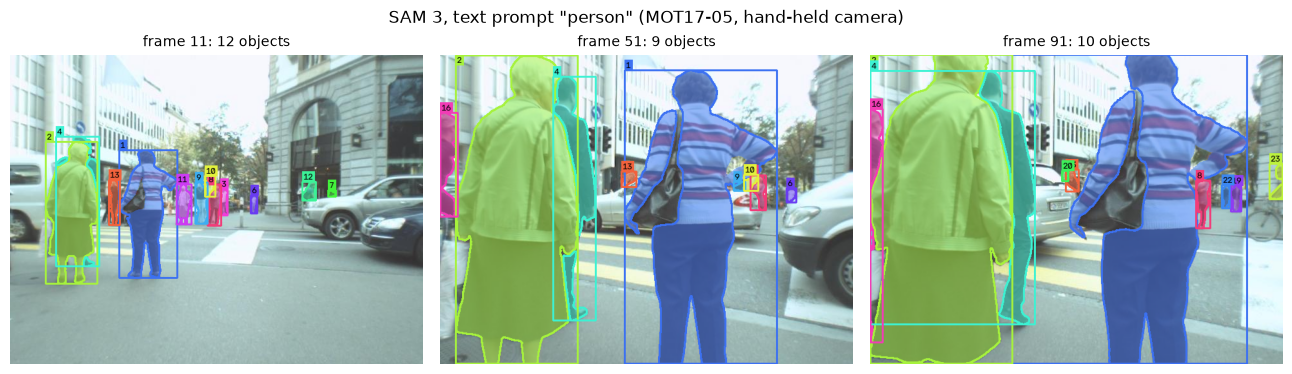

assets/06_tracking/sam3_mot17_05.gif 0.78 MB


In [4]:
# --- Figure: SAM 3 masks + ids on three frames; GIF for the README ---
imgs, titles = [], []
for f, (ids, masks) in sorted(sam["masks"].items()):
    img = cvlab.viz.overlay_masks(frames[f], masks, alpha=0.5, colors=[ml.id_color(i) for i in ids])
    imgs.append(ml.draw_tracks(img, sam_rows[sam_rows[:, 0] == f + 1]))
    titles.append(f"frame {f + 1}: {len(ids)} objects")
fig = cvlab.viz.show_images(imgs, ncols=3, size=4.3, titles=titles,
                            suptitle='SAM 3, text prompt "person" (MOT17-05, hand-held camera)')
cvlab.viz.savefig(fig, PROJECT, "sam3_masks")
plt.show()
gif = cvlab.viz.save_gif([overlays[f] for f in sorted(overlays)],
                         cvlab.io.assets_dir(PROJECT) / "sam3_mot17_05.gif", fps=7)
print(gif.relative_to(ROOT), f"{gif.stat().st_size / 1e6:.2f} MB")

## 3. The baseline on the same frames: YOLO26s + ByteTrack / BoT-SORT

We detect the same 100 frames with YOLO26s (fp16, `conf=0.1`) and run the trackers from
notebook 01 on the cached detections. We call `predict` once per frame, as a robot would on a
live stream. Gotcha: passing a Python *list* of 100 paths as `source` makes Ultralytics decode
all of them up front and run them as **one batch of 100 images** (we measured about 1.8 GB of
VRAM for that), which is offline throughput, not per-frame latency. Everything is scored with `motlib.evaluate`
(MOT17 protocol: pedestrians only, distractor matches removed) on frames 1-100.

In [5]:
# --- YOLO26s detections for the snippet, then ByteTrack and BoT-SORT (GMC) ---
yolo = YOLO(str(cvlab.io.weights_dir("ultralytics", "yolo26s.pt")))
paths = [str(SEQ.frame_path(t)) for t in range(1, N_FRAMES + 1)]
fr, xyxy, conf = [], [], []
# SAM 3 stays loaded (exercises), so the allocator peak would include its ~1.6 GB of weights:
# we report the YOLO pipeline's own share = peak - memory already allocated before it starts.
base_mb = torch.cuda.memory_allocated() / 2**20
with cvlab.device.track_vram() as mem_yolo:
    yolo.predict(paths[0], imgsz=640, quantize=16, device=0, verbose=False)  # warm-up, weights -> GPU
    t0 = time.perf_counter()
    for t, path in enumerate(paths, start=1):  # one frame per call, like a live camera stream
        r = yolo.predict(path, conf=0.1, classes=[0], imgsz=640, quantize=16, device=0, verbose=False)[0]
        b = r.boxes.cpu().numpy()
        fr.append(np.full(len(b), t))
        xyxy.append(b.xyxy)
        conf.append(b.conf)
    yolo_seconds = time.perf_counter() - t0
dets = ml.DetectionCache(np.concatenate(fr), np.concatenate(xyxy), np.concatenate(conf))
yolo_vram_mb = mem_yolo.peak_mb - base_mb  # MiB used by YOLO26s itself (weights + activations)
print(f"YOLO26s: {N_FRAMES} frames in {yolo_seconds:.2f} s, own peak VRAM {yolo_vram_mb:.0f} MiB "
      f"(on top of {base_mb:.0f} MiB already allocated)")
runs = {"SAM 3 (text: person)": {"rows": sam_rows, "FPS": sam["fps"], "peak VRAM [MiB]": sam["peak_vram_mb"]}}
for label, cfg in [("YOLO26s + ByteTrack", "bytetrack.yaml"), ("YOLO26s + BoT-SORT (GMC)", "botsort.yaml")]:
    rows_t, timing = ml.run_tracker(ml.make_tracker(str(CFG_DIR / cfg)), dets, N_FRAMES,
                                    frame_loader=lambda t: cv2.imread(paths[t - 1]))
    fps = N_FRAMES / (yolo_seconds + N_FRAMES * timing["tracker_ms_per_frame"] / 1000)
    runs[label] = {"rows": rows_t, "FPS": fps, "peak VRAM [MiB]": yolo_vram_mb}
table = {}
for label, r in runs.items():
    res = ml.evaluate(gt, r["rows"], N_FRAMES)
    table[label] = {**ml.summary_row(res), "FPS": round(r["FPS"], 2),
                    "peak VRAM [MiB]": round(r["peak VRAM [MiB]"]),
                    "distractor boxes removed": res["removed_distractor_matches"]}
cols = ["HOTA", "DetA", "AssA", "LocA", "MOTA", "IDF1", "MOTP", "IDSW", "CLR_FP", "CLR_FN",
        "FPS", "peak VRAM [MiB]", "distractor boxes removed"]
cmp_df = pd.DataFrame(table).T[cols]
display(cmp_df)

YOLO26s: 100 frames in 0.41 s, own peak VRAM 37 MiB (on top of 1717 MiB already allocated)


,HOTA,DetA,AssA,LocA,MOTA,IDF1,MOTP,IDSW,CLR_FP,CLR_FN,FPS,peak VRAM [MiB],distractor boxes removed
SAM 3 (text: person),46.06,38.70,56.12,74.85,17.77,56.93,72.08,8.0,323.0,326.0,0.57,3771.0,25.0
YOLO26s + ByteTrack,41.22,31.67,54.54,78.43,21.53,50.53,74.41,14.0,220.0,393.0,224.74,37.0,5.0
YOLO26s + BoT-SORT (GMC),42.80,33.11,56.38,79.04,25.03,52.71,74.71,9.0,215.0,375.0,133.71,37.0,11.0


## 4. Modal masks vs amodal ground truth

MOT17 GT boxes are **amodal**: they enclose the full body even when half of it is hidden.
SAM 3's boxes come from its masks, so they are **modal** (visible part only), just like a
detector that was never trained on amodal boxes. For partly occluded people this lowers the
IoU with the GT, which costs matches at IoU 0.5 and lowers LocA / MOTP. We split the matched
pairs by the GT visibility ratio (9th column of `gt.txt`) to see the effect.

SAM 3 (text: person)       mean IoU per visibility bin: 0.641 (n=184), 0.687 (n=94), 0.813 (n=195)
YOLO26s + BoT-SORT (GMC)   mean IoU per visibility bin: 0.622 (n=142), 0.720 (n=92), 0.854 (n=190)


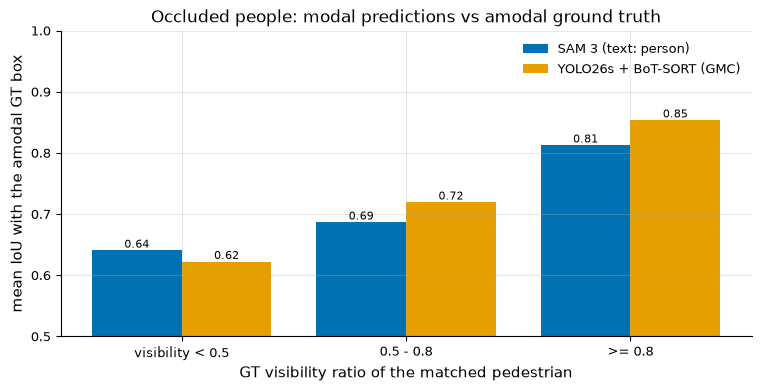

In [6]:
# --- IoU of matched (GT, prediction) pairs vs the GT visibility ratio ---
def matched_ious(rows):
    data = ml.prepare_mot17(gt, rows, N_FRAMES)
    clr = ml.clear_metrics(data, return_matches=True)
    out = []
    for t, gid, tid in clr["matches"]:
        g = gt[(gt[:, 0] == t + 1) & (gt[:, 1] == gid)][0]
        p = rows[(rows[:, 0] == t + 1) & (rows[:, 1] == tid)][0]
        iou = cvlab.metrics.box_iou(ml.xywh_to_xyxy(g[2:6]), ml.xywh_to_xyxy(p[2:6]))[0, 0]
        out.append((g[8], iou))
    return np.asarray(out)


bins = [0.0, 0.5, 0.8, 1.01]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for k, label in enumerate(["SAM 3 (text: person)", "YOLO26s + BoT-SORT (GMC)"]):
    vi = matched_ious(runs[label]["rows"])
    idx = np.digitize(vi[:, 0], bins) - 1
    means = [vi[idx == b, 1].mean() for b in range(3)]
    counts = [int((idx == b).sum()) for b in range(3)]
    print(f"{label:26s} mean IoU per visibility bin: "
          + ", ".join(f"{m:.3f} (n={c})" for m, c in zip(means, counts)))
    bars = ax.bar(np.arange(3) + (k - 0.5) * 0.4, means, width=0.4, label=label)
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
ax.set_xticks(range(3), ["visibility < 0.5", "0.5 - 0.8", ">= 0.8"])
ax.set_xlabel("GT visibility ratio of the matched pedestrian")
ax.set_ylabel("mean IoU with the amodal GT box")
ax.set_ylim(0.5, 1.0)
ax.set_title("Occluded people: modal predictions vs amodal ground truth")
ax.legend()
plt.show()

## Results

Same 100 frames of MOT17-05, same MOT17 protocol and metric code, RTX 5060 Laptop GPU (8 GB).
FPS for the YOLO pipelines counts detection (GPU, incl. JPEG decoding) plus tracking (CPU);
for SAM 3 it is the propagation loop (video pre-processing excluded). Peak VRAM is the
allocator peak of each pipeline on its own (for YOLO26s: the increase over the memory that was
already allocated, since SAM 3 stays loaded).

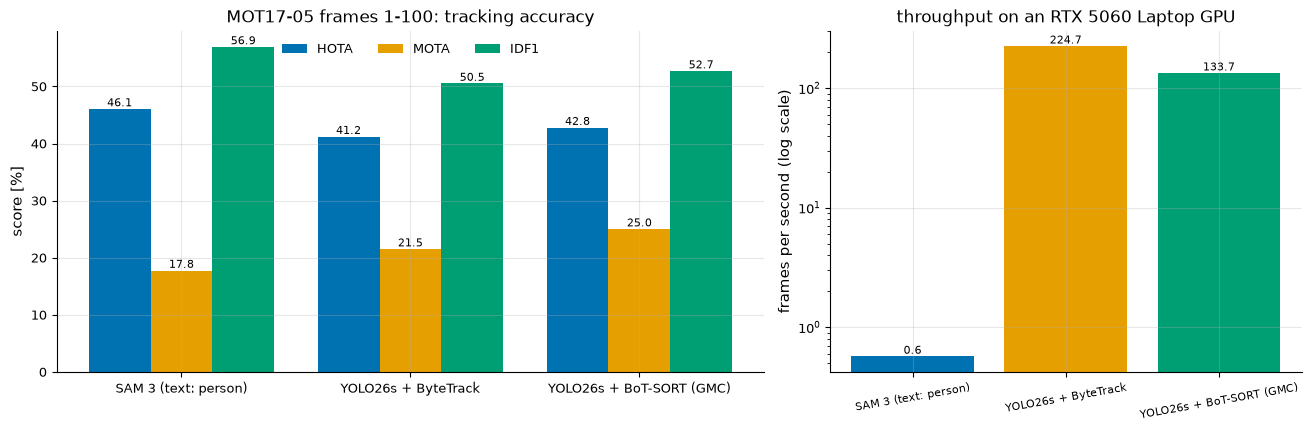

,HOTA,DetA,AssA,LocA,MOTA,IDF1,MOTP,IDSW,CLR_FP,CLR_FN,FPS,peak VRAM [MiB],distractor boxes removed
SAM 3 (text: person),46.06,38.70,56.12,74.85,17.77,56.93,72.08,8.0,323.0,326.0,0.57,3771.0,25.0
YOLO26s + ByteTrack,41.22,31.67,54.54,78.43,21.53,50.53,74.41,14.0,220.0,393.0,224.74,37.0,5.0
YOLO26s + BoT-SORT (GMC),42.80,33.11,56.38,79.04,25.03,52.71,74.71,9.0,215.0,375.0,133.71,37.0,11.0


In [7]:
# --- Figure: accuracy (HOTA / MOTA / IDF1) and throughput of the three pipelines ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [3, 2]})
x = np.arange(len(cmp_df))
for k, metric in enumerate(["HOTA", "MOTA", "IDF1"]):
    bars = axes[0].bar(x + (k - 1) * 0.27, cmp_df[metric].astype(float), width=0.27, label=metric)
    axes[0].bar_label(bars, fmt="%.1f", fontsize=8)
axes[0].set_xticks(x, cmp_df.index, fontsize=9)
axes[0].set_ylabel("score [%]")
axes[0].set_title(f"MOT17-05 frames 1-{N_FRAMES}: tracking accuracy")
axes[0].legend(ncol=3)
bars = axes[1].bar(x, cmp_df["FPS"].astype(float), color=[cvlab.viz.color(i, unit=True) for i in range(3)])
axes[1].bar_label(bars, fmt="%.1f", fontsize=8)
axes[1].set_yscale("log")
axes[1].set_xticks(x, cmp_df.index, fontsize=8, rotation=10)
axes[1].set_ylabel("frames per second (log scale)")
axes[1].set_title("throughput on an RTX 5060 Laptop GPU")
cvlab.viz.savefig(fig, PROJECT, "sam3_vs_trackers")
plt.show()
display(cmp_df)

### Takeaways

* **SAM 3 keeps identities best, but loses on MOTA.** On the same 100 frames, SAM 3 ("person")
  reaches HOTA 46.06 and IDF1 56.93 with 8 ID switches, against 42.80 / 52.71 / 9 for
  YOLO26s + BoT-SORT (GMC) and 41.22 / 50.53 / 14 for YOLO26s + ByteTrack. Its MOTA is the
  lowest (17.77 vs 25.03 / 21.53): it misses fewer pedestrians (FN 326 vs 375 / 393) but
  produces more boxes that do not reach IoU 0.5 with an annotated pedestrian (FP 323 vs
  215 / 220). MOTA counts each of them as a full error, while HOTA averages over IoU thresholds
  from 0.05 to 0.95 and also credits loosely overlapping boxes. Read both.
* **Modal masks vs amodal boxes.** For well-visible people (visibility >= 0.8) SAM 3's
  mask-derived boxes overlap the GT less than the YOLO26s boxes (mean IoU 0.813 vs 0.854),
  which shows up as a lower LocA (74.85 vs 79.04). For heavily occluded people
  (visibility < 0.5) SAM 3 matches more of them (184 vs 142 matched boxes) at a similar IoU
  (0.641 vs 0.622).
* **The price is speed.** SAM 3 processed 0.57 frames per second (peak VRAM 3 771 MiB, with
  the tracker state in CPU RAM; on the GPU the state ran out of memory before frame 100). The
  YOLO26s pipelines ran at 224.74 (ByteTrack) and 133.71 (BoT-SORT) frames per second, using
  37 MiB of VRAM of their own: about 390x and 235x faster.
* **Where it fits in a robot.** The text prompt replaces a closed label set, so the same model
  can track any noun phrase without new training data (exercise 1). At under one frame per
  second it is an offline labelling tool or a slow "find this object" module; the real-time
  loop remains a detector + motion tracker, possibly trained on labels that SAM 3 produced.

## Exercises

Solutions: `projects/06_tracking/solutions/`.

**Exercise 1: open vocabulary.** Prompt SAM 3 with other concepts on the same snippet
(e.g. `"car"`, `"bag"`, `"traffic light"`) and report how many objects and distinct ids each
prompt yields. Which of these could a COCO-trained YOLO also find, and which not?

In [8]:
# --- Exercise 1: other text prompts on the same frames ---
# TODO: for prompt in [...]: r = sam3video.track_concept(sam3, sam3_proc, frames[:30], prompt)
# and count len(np.unique(r["rows"][:, 1])) and the boxes per frame.

**Exercise 2: the new-object threshold.** SAM 3 only starts a new masklet for detections with
score >= `sam3.new_det_thresh` (0.7). Lower it to 0.5 and raise it to 0.85 (set the attribute
on the loaded model), re-run the first 50 frames (keeps the sweep to a few minutes; include the
default 0.7 as the reference row) and compare FP, FN, IDSW and HOTA.

In [9]:
# --- Exercise 2: sweep the new-detection threshold ---
# TODO: sam3.new_det_thresh = value; run sam3video.track_concept(...) and ml.evaluate(gt, rows, N_FRAMES);
# restore the default (0.7) afterwards.